In [12]:
import os
from google.colab import drive

# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Definir o caminho direto para a pasta no teu Google Drive
CAMINHO_DATA = '/content/drive/MyDrive/Projeto_Futebol/data'

# Verificar se a pasta existe
if os.path.exists(CAMINHO_DATA):
    print("✅ Google Drive ligado com sucesso! Ficheiros encontrados em:")
    print(CAMINHO_DATA)
    print("\nFicheiros disponíveis:", os.listdir(CAMINHO_DATA))
else:
    print("⚠️ Caminho não encontrado. Verifica o nome da pasta no Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive ligado com sucesso! Ficheiros encontrados em:
/content/drive/MyDrive/Projeto_Futebol/data

Ficheiros disponíveis: ['2020-2021.csv', '2021-2022.csv', '2000-01.csv', '2001-02.csv', '2002-03.csv', '2003-04.csv', '2004-05.csv', '2005-06.csv', '2006-07.csv', '2007-08.csv', '2008-09.csv', '2009-10.csv', '2010-11.csv', '2011-12.csv', '2012-13.csv', '2013-14.csv', '2014-15.csv', '2015-16.csv', '2016-17.csv', '2017-18.csv', '2018-19.csv', '2019-20.csv']


# 1. Business and Data Understanding (Metodologia CRISP-ML)

## 1.1. Enquadramento e Objetivos
Nesta fase inicial, o objetivo é inspecionar e compreender a fundo o conjunto de dados de partidas de futebol recolhido. Explora-se a estrutura das tabelas, valida-se a qualidade da informação (procurando valores ausentes e duplicados) e realiza-se uma **Análise Exploratória de Dados (EDA)** completa.

Nesta análise abordam-se:
- **Resumo Estrutural:** Identificação de colunas, registos e tipos de dados.
- **Diagnóstico de Qualidade:** Identificação de linhas duplicadas e dados nulos.
- **Análise Univariada:** Estatísticas descritivas, Assimetria (*Skewness*) e Achatamento (*Kurtosis*).
- **Análise Bivariada:** Estudo da variável alvo `FTR` (*Full Time Result*: Vitórias `H`, Empates `D`, Vitórias Visitante `A`).
- **Análise Multivariada:** Comparação de matrizes de correlação de **Pearson** (relações lineares) e **Spearman** (relações monotónicas).

In [13]:
# Importação das bibliotecas principais
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configurações estéticas globais dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1.2. Módulo de Carregamento e Unificação dos Datasets
Esta função procura todos os ficheiros `.csv` referentes às épocas presentes na pasta do projeto (`data/`), carrega-os tratando eventuais problemas de *encoding* e junta-os num único **DataFrame global**, ignorando ficheiros auxiliares (como tabelas de classificação) e preservando o identificador da época correspondente.

In [14]:
def carregar_e_unificar_datasets(caminho_pasta: str):
    """Procura todos os CSVs na pasta, carrega-os com tratamento de encoding e
    cria um DataFrame unificado.
    """
    ficheiros_csv = sorted(glob.glob(os.path.join(caminho_pasta, "*.csv")))

    if not ficheiros_csv:
        print(f"[ERRO] Nenhum ficheiro CSV encontrado na pasta '{caminho_pasta}'.")
        return None, {}

    datasets_individuais = {}
    lista_dfs = []

    for caminho in ficheiros_csv:
        nome_f = os.path.basename(caminho)
        try:
            df_temp = pd.read_csv(caminho, encoding="utf-8")
        except UnicodeDecodeError:
            df_temp = pd.read_csv(caminho, encoding="latin1")

        # Guardar a época correspondente com base no nome do ficheiro
        df_temp["Epoca"] = nome_f.replace(".csv", "")
        datasets_individuais[nome_f] = df_temp
        lista_dfs.append(df_temp)

    df_unificado = pd.concat(lista_dfs, ignore_index=True)

    print(
        f"[SUCESSO] {len(ficheiros_csv)} ficheiros carregados da pasta"
        f" '{caminho_pasta}'."
    )
    print(
        f"           Total de Registos: {df_unificado.shape[0]} | Colunas:"
        f" {df_unificado.shape[1]}\n"
    )

    return df_unificado, datasets_individuais

## 1.3. Inspeção da Estrutura Geral dos Dados
Permite obter uma visão geral dos dados através da visualização das primeiras linhas, contagem dos tipos de dados (numéricos, texto/objeto) e resumo técnico do DataFrame (`.info()`).

In [15]:
def resumo_estrutura(df: pd.DataFrame, nome_dataset: str = "Dataset Global"):
    """Exibe um resumo detalhado da estrutura: head(), dtypes e .info()."""
    print("=" * 70)
    print(f"1. RESUMO DA ESTRUTURA DOS DADOS: {nome_dataset}")
    print("=" * 70)
    print("\n--- Primeiras 5 linhas ---")
    print(df.head())

    print("\n--- Contagem dos Tipos de Dados ---")
    print(df.dtypes.value_counts())

    print("\n--- Detalhe das Colunas e Tipos (.info()) ---")
    df.info()
    print("\n")

## 1.4. Análise da Qualidade dos Dados (Nulos e Duplicados)
Esta etapa analisa se existem registos inteiramente duplicados e calcula a percentagem e quantidade absoluta de valores omissos (*missing values*) por variável.

In [16]:
def analisar_qualidade_dados(df: pd.DataFrame):
    """Analisa a presença de registos duplicados e de valores nulos/ausentes."""
    print("=" * 70)
    print("2. ANÁLISE DE QUALIDADE DOS DADOS (NULOS E DUPLICADOS)")
    print("=" * 70)

    duplicados = df.duplicated().sum()
    print(f"Linhas duplicadas encontradas: {duplicados}")

    nulos_col = df.isnull().sum()
    perc_nulos = (nulos_col / len(df)) * 100

    relatorio_nulos = (
        pd.DataFrame({"Valores_Nulos": nulos_col, "Percentagem_%": perc_nulos})
        .query("Valores_Nulos > 0")
        .sort_values(by="Valores_Nulos", ascending=False)
    )

    if relatorio_nulos.empty:
        print("Não foram encontrados valores nulos.")
    else:
        print("\nTop 15 Colunas com Mais Valores Ausentes:")
        print(relatorio_nulos.head(15))
    print("\n")

## 1.5. Análise Univariada e Estatística Descritiva Avançada
Nesta subsecção calculam-se as métricas estatísticas descritivas padrão (média, desvio padrão, mínimos, quartis e máximos) e complementa-se com métricas avançadas:
- **Assimetria (*Skewness*):** Indica o desvio de simetria em relação a uma distribuição normal.
- **Achatamento (*Kurtosis*):** Avalia a presença de valores extremos/discrepantes nas caudas da distribuição.

In [17]:
def estatisticas_descritivas_completas(df: pd.DataFrame):
    """Apresenta métricas descritivas para variáveis numéricas e categóricas,
    incluindo Skewness (Assimetria) e Kurtosis (Achatamento).
    """
    print("=" * 70)
    print("3. ESTATÍSTICAS DESCRITIVAS E EDA AVANÇADA")
    print("=" * 70)

    colunas_num = df.select_dtypes(include=[np.number])

    print("\n--- Variáveis Numéricas (Resumo Clássico) ---")
    print(colunas_num.describe().T[["mean", "std", "min", "50%", "max"]].head(15))

    print("\n--- Estatística Avançada: Skewness (Assimetria) e Kurtosis ---")
    estat_avancadas = pd.DataFrame(
        {"Skewness (Assimetria)": colunas_num.skew(), "Kurtosis": colunas_num.kurt()}
    )
    print(estat_avancadas.head(15))

    colunas_cat = df.select_dtypes(include=["object", "category"]).columns
    if len(colunas_cat) > 0:
        print("\n--- Variáveis Categóricas / Texto ---")
        print(df.describe(include=["object", "category"]).T.head(10))
    print("\n")

## 1.6. Análise Bivariada: Variável Alvo (`FTR`)
Analisa a distribuição da variável alvo `FTR` (*Full Time Result*). Identifica a contagem e proporção de jogos que terminaram em Vitória da Casa (`H`), Empate (`D`) ou Vitória do Visitante (`A`), gerando gráficos de barras e gráficos circulares.

In [18]:
def analisar_variavel_alvo(df: pd.DataFrame, coluna_alvo: str = "FTR"):
    """Analisa e visualiza a distribuição da variável alvo FTR (H, D, A)."""
    print("=" * 70)
    print(f"4. ANÁLISE DA VARIÁVEL ALVO: '{coluna_alvo}'")
    print("=" * 70)

    if coluna_alvo not in df.columns:
        print(f"A coluna '{coluna_alvo}' não se encontra no dataset.\n")
        return

    df_valido = df.dropna(subset=[coluna_alvo])
    contagem = df_valido[coluna_alvo].value_counts()
    percentagem = df_valido[coluna_alvo].value_counts(normalize=True) * 100

    print(
        pd.DataFrame({"Total Jogos": contagem, "Percentagem_%": percentagem})
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico de Barras
    sns.countplot(
        x=coluna_alvo,
        data=df_valido,
        order=["H", "D", "A"],
        palette="viridis",
        ax=axes[0],
        hue=coluna_alvo,
        legend=False,
    )
    axes[0].set_title(
        "Distribuição do Resultado Final (H: Casa, D: Empate, A: Visitante)"
    )
    axes[0].set_xlabel("Resultado")
    axes[0].set_ylabel("Quantidade de Jogos")

    # Gráfico Circular
    axes[1].pie(
        contagem,
        labels=contagem.index,
        autopct="%1.1f%%",
        colors=sns.color_palette("viridis", 3),
        startangle=90,
    )
    axes[1].set_title("Proporção dos Resultados")

    plt.tight_layout()
    plt.show()
    print("\n")

## 1.7. Análise Multivariada: Matrizes de Correlação (Pearson vs Spearman)
Para estudar a interdependência entre as variáveis do jogo (golos, remates, cantos, faltas, cartões), comparam-se duas abordagens estatísticas:
1. **Pearson:** Mede a associação linear entre variáveis numéricas contínuas.
2. **Spearman:** Mede a associação monotónica baseada em *ranks* (ordem), sendo mais resistente a valores discrepantes (*outliers*).

In [19]:
def analisar_correlacoes_completas(df: pd.DataFrame):
    """Compara as matrizes de correlação de Pearson (Linear) e Spearman (Monotónica)
    para as principais estatísticas de jogo.
    """
    print("=" * 70)
    print("5. ANÁLISE MULTIVARIADA DE CORRELAÇÃO (PEARSON VS SPEARMAN)")
    print("=" * 70)

    colunas_chave = [
        "FTHG", "FTAG", "HTHG", "HTAG", "HS", "AS", "HST", "AST",
        "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR"
    ]
    colunas_presentes = [c for c in colunas_chave if c in df.columns]

    if len(colunas_presentes) > 1:
        df_corr = df[colunas_presentes]

        fig, axes = plt.subplots(1, 2, figsize=(18, 7))

        # Heatmap Pearson
        sns.heatmap(
            df_corr.corr(method="pearson"),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            center=0,
            ax=axes[0],
            cbar=False,
        )
        axes[0].set_title("Correlação de Pearson (Linear)")

        # Heatmap Spearman
        sns.heatmap(
            df_corr.corr(method="spearman"),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            center=0,
            ax=axes[1],
            cbar=False,
        )
        axes[1].set_title("Correlação de Spearman (Monotónica)")

        plt.tight_layout()
        plt.show()
    else:
        print("Não foram encontradas métricas de jogo suficientes.")
    print("\n")

## 1.8. Execução Global do Pipeline de Data Understanding
Nesta célula final, deteta-se automaticamente a localização da pasta `data` (dando prioridade ao caminho configurado no Google Drive), executando sequencialmente todas as funções declaradas para gerar o relatório consolidado.

[SUCESSO] 22 ficheiros carregados da pasta '/content/drive/MyDrive/Projeto_Futebol/data'.
           Total de Registos: 8020 | Colunas: 145

1. RESUMO DA ESTRUTURA DOS DADOS: Dataset Unificado

--- Primeiras 5 linhas ---
  Div      Date  HomeTeam       AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  19/08/00  Charlton       Man City     4     0   H     2     0   H  ...   
1  E0  19/08/00   Chelsea       West Ham     4     2   H     1     0   H  ...   
2  E0  19/08/00  Coventry  Middlesbrough     1     3   A     1     1   D  ...   
3  E0  19/08/00     Derby    Southampton     2     2   D     1     2   A  ...   
4  E0  19/08/00     Leeds        Everton     2     0   H     2     0   H  ...   

   AvgC<2.5 AHCh  B365CAHH  B365CAHA  PCAHH  PCAHA  MaxCAHH  MaxCAHA  AvgCAHH  \
0       NaN  NaN       NaN       NaN    NaN    NaN      NaN      NaN      NaN   
1       NaN  NaN       NaN       NaN    NaN    NaN      NaN      NaN      NaN   
2       NaN  NaN       NaN       NaN    NaN    Na

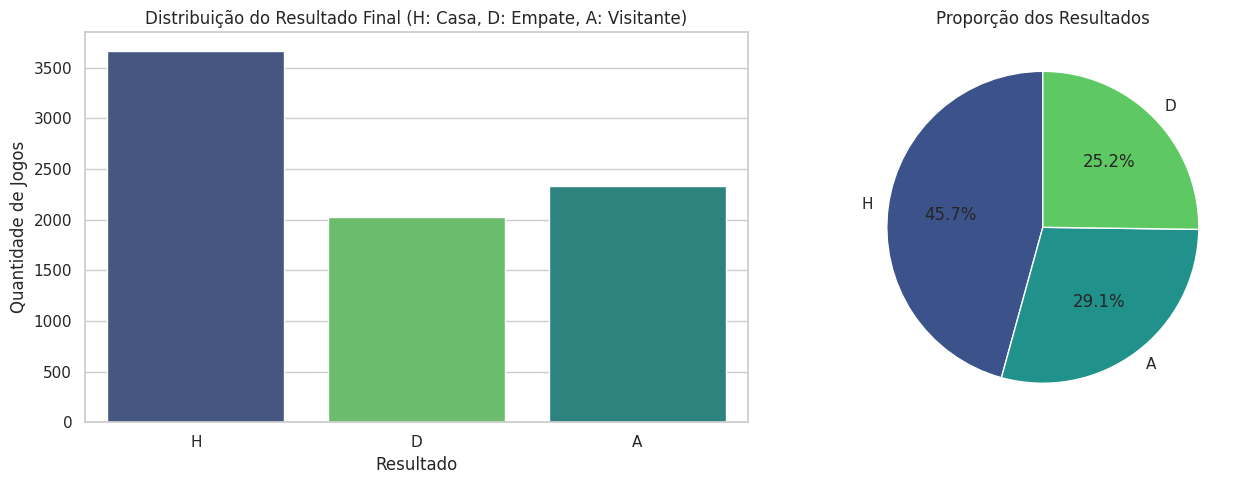



5. ANÁLISE MULTIVARIADA DE CORRELAÇÃO (PEARSON VS SPEARMAN)


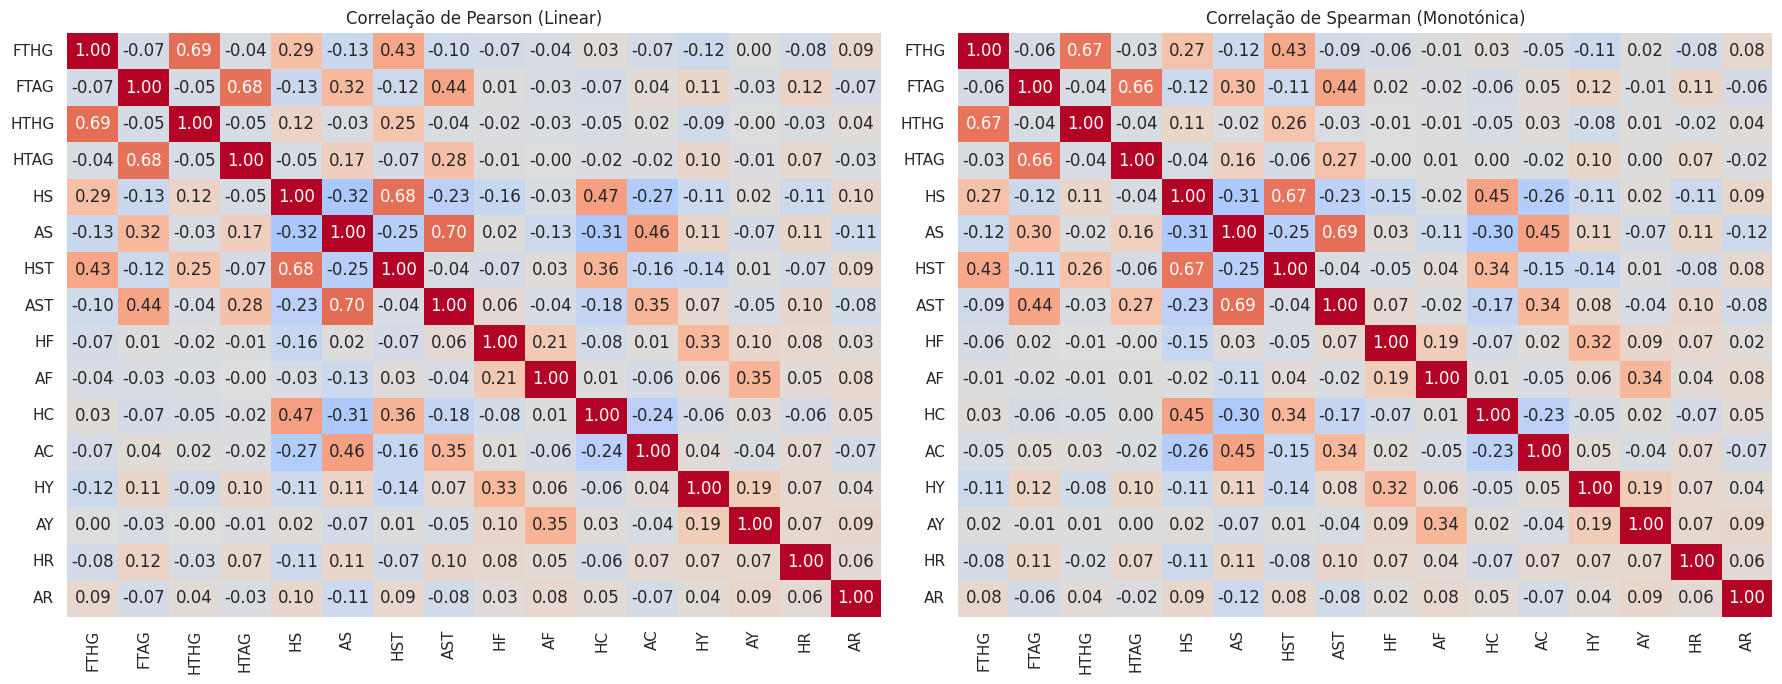

In [20]:
# Detetar a pasta de dados no Google Colab com prioridade ao Google Drive
possiveis_caminhos = [
    '/content/drive/MyDrive/Projeto_Futebol/data',
    './data',
    '/data',
    '/content/data'
]

# Se a variável CAMINHO_DATA tiver sido definida na Célula 1, garante que ela é testada primeiro
if 'CAMINHO_DATA' in globals() and os.path.exists(CAMINHO_DATA):
    possiveis_caminhos.insert(0, CAMINHO_DATA)

caminho_pasta = None

for path in possiveis_caminhos:
    if os.path.exists(path) and glob.glob(os.path.join(path, "*.csv")):
        caminho_pasta = path
        break

if caminho_pasta is None:
    print(
        "[ERRO] A pasta 'data' não foi encontrada. Certifica-te de que criaste a"
        " pasta com os CSVs no Google Drive ou Colab."
    )
else:
    # 1. Carregar e unificar datasets
    df_futebol, datasets_individuais = carregar_e_unificar_datasets(caminho_pasta)

    if df_futebol is not None:
        # 2. Resumo da estrutura geral
        resumo_estrutura(df_futebol, nome_dataset="Dataset Unificado")

        # 3. Qualidade dos Dados (Duplicados e Nulos)
        analisar_qualidade_dados(df_futebol)

        # 4. Estatística Descritiva + Skewness e Kurtosis
        estatisticas_descritivas_completas(df_futebol)

        # 5. Análise da Variável Alvo (FTR)
        analisar_variavel_alvo(df_futebol, coluna_alvo="FTR")

        # 6. Matrizes de Correlação (Pearson vs Spearman)
        analisar_correlacoes_completas(df_futebol)

# 2. Data Preparation (Metodologia CRISP-ML)

## 2.1. Objetivos e Estratégia de Limpeza
Nesta fase, transformamos os dados brutos recolhidos num conjunto de dados estruturado, consistente e pronto para a fase de Modelação.

### Passos da Preparação:
1. **Seleção de Colunas Relevantes:** Filtrar as variáveis estatísticas essenciais do jogo (Golos, Remates, Remates à Baliza, Cantos, Faltas, Cartões) e remover odds secundárias ou instáveis com taxa elevada de nulos.
2. **Padronização de Datas e Ordenação Cronológica:** Converter a coluna `Date` num formato `datetime` único e ordenar o dataset sequencialmente por época e data para evitar o *data leakage* em análises temporais.
3. **Tratamento de Inconsistências e Nulos:** Remover registos sem resultado (`FTR`) ou equipas definidas e tratar valores omissos em estatísticas secundárias.
4. **Engenharia de Funcionalidades (*Feature Engineering* Base):** Criar variáveis pré-jogo com base no histórico recente de cada equipa:
   - Média móvel de golos marcados/sofridos nos últimos 5 jogos.
   - Pontos acumulados na época.
   - Forma recente da equipa (pontos conquistados nos últimos 5 jogos).
5. **Exportação do Dataset Final:** Guardar a versão final consolidada e limpa no Google Drive.

In [21]:
import pandas as pd
import numpy as np

def limpar_e_selecionar_colunas(df: pd.DataFrame) -> pd.DataFrame:
    """Limpa e padroniza as colunas essenciais do dataset de futebol."""
    df_clean = df.copy()

    # 1. Colunas Chave a preservar (se existirem no dataset)
    colunas_essenciais = [
        "Epoca", "Date", "HomeTeam", "AwayTeam",
        "FTHG", "FTAG", "FTR",          # Golos e Resultado Final
        "HTHG", "HTAG", "HTR",          # Golos e Resultado ao Intervalo
        "HS", "AS", "HST", "AST",       # Remates e Remates à Baliza
        "HF", "AF", "HC", "AC",         # Faltas e Cantos
        "HY", "AY", "HR", "AR"          # Cartões Amarelos e Vermelhos
    ]

    # Preservar apenas as colunas disponíveis que interessam
    colunas_presentes = [col for col in colunas_essenciais if col in df_clean.columns]
    df_clean = df_clean[colunas_presentes]

    # 2. Remover registos fundamentais que estejam sem valor (ex: sem FTR ou equipa)
    df_clean = df_clean.dropna(subset=["HomeTeam", "AwayTeam", "FTR"])

    # 3. Converter e padronizar o formato de datas (lidando com múltiplos formatos como YY e YYYY)
    df_clean["Date"] = pd.to_datetime(df_clean["Date"], dayfirst=True, format="mixed", errors="coerce")
    df_clean = df_clean.dropna(subset=["Date"])

    # 4. Ordenar cronologicamente
    df_clean = df_clean.sort_values(by=["Date"]).reset_index(drop=True)

    # 5. Limpeza de textos/nomes das equipas (remover espaços extra)
    df_clean["HomeTeam"] = df_clean["HomeTeam"].astype(str).str.strip()
    df_clean["AwayTeam"] = df_clean["AwayTeam"].astype(str).str.strip()

    # 6. Preenchimento de nulos secundários nas estatísticas de jogo pela mediana da coluna
    colunas_num = df_clean.select_dtypes(include=[np.number]).columns
    df_clean[colunas_num] = df_clean[colunas_num].fillna(df_clean[colunas_num].median())

    print(f"[LIMPEZA CONCLUÍDA] Registos restantes: {df_clean.shape[0]} | Colunas: {df_clean.shape[1]}")
    return df_clean

## 2.2. Engenharia de Funcionalidades (*Feature Engineering*)
Para prever resultados de jogos futuros de forma realista, os modelos não podem utilizar as estatísticas do próprio jogo (ex: remates no jogo atual). Por isso, calculam-se **métricas acumuladas pré-jogo** baseadas no desempenho histórico das equipas até esse momento:
- `Home_Points_Pre`, `Away_Points_Pre`: Pontos acumulados na época antes do jogo.
- `Home_Golos_Marcados_L5`, `Away_Golos_Marcados_L5`: Média de golos marcados nos últimos 5 jogos.
- `Home_Golos_Sofridos_L5`, `Away_Golos_Sofridos_L5`: Média de golos sofridos nos últimos 5 jogos.
- `Home_Forma_L5`, `Away_Forma_L5`: Total de pontos somados nas últimas 5 partidas.

In [22]:
def calcular_features_acumuladas(df: pd.DataFrame, window: int = 5) -> pd.DataFrame:
    """Gera variáveis de histórico recente (média móvel) e pontos pré-jogo para cada equipa."""
    df_feat = df.copy()

    # Mapeamento de pontos por resultado
    def get_points_home(ftr):
        return 3 if ftr == "H" else (1 if ftr == "D" else 0)

    def get_points_away(ftr):
        return 3 if ftr == "A" else (1 if ftr == "D" else 0)

    df_feat["HomePoints"] = df_feat["FTR"].apply(get_points_home)
    df_feat["AwayPoints"] = df_feat["FTR"].apply(get_points_away)

    # Estruturas para guardar o histórico
    historico_equipas = {}

    # Listas para guardar as novas features pré-jogo
    home_gm_l5, away_gm_l5 = [], []
    home_gs_l5, away_gs_l5 = [], []
    home_forma_l5, away_forma_l5 = [], []

    for idx, row in df_feat.iterrows():
        h_team = row["HomeTeam"]
        a_team = row["AwayTeam"]

        # Inicializar histórico se a equipa for nova
        for team in [h_team, a_team]:
            if team not in historico_equipas:
                historico_equipas[team] = {"GM": [], "GS": [], "Pts": []}

        # Extrair dados históricos Pré-Jogo (antes de atualizar com o jogo atual)
        h_hist = historico_equipas[h_team]
        a_hist = historico_equipas[a_team]

        # Calcular métricas dos últimos N jogos
        home_gm_l5.append(np.mean(h_hist["GM"][-window:]) if len(h_hist["GM"]) > 0 else 0)
        away_gm_l5.append(np.mean(a_hist["GM"][-window:]) if len(a_hist["GM"]) > 0 else 0)

        home_gs_l5.append(np.mean(h_hist["GS"][-window:]) if len(h_hist["GS"]) > 0 else 0)
        away_gs_l5.append(np.mean(a_hist["GS"][-window:]) if len(a_hist["GS"]) > 0 else 0)

        home_forma_l5.append(np.sum(h_hist["Pts"][-window:]) if len(h_hist["Pts"]) > 0 else 0)
        away_forma_l5.append(np.sum(a_hist["Pts"][-window:]) if len(a_hist["Pts"]) > 0 else 0)

        # Atualizar histórico com os dados do jogo atual
        h_hist["GM"].append(row["FTHG"])
        h_hist["GS"].append(row["FTAG"])
        h_hist["Pts"].append(row["HomePoints"])

        a_hist["GM"].append(row["FTAG"])
        a_hist["GS"].append(row["FTHG"])
        a_hist["Pts"].append(row["AwayPoints"])

    # Adicionar as novas variáveis ao DataFrame
    df_feat[f"Home_Golos_Marcados_L{window}"] = home_gm_l5
    df_feat[f"Away_Golos_Marcados_L{window}"] = away_gm_l5
    df_feat[f"Home_Golos_Sofridos_L{window}"] = home_gs_l5
    df_feat[f"Away_Golos_Sofridos_L{window}"] = away_gs_l5
    df_feat[f"Home_Forma_L{window}"] = home_forma_l5
    df_feat[f"Away_Forma_L{window}"] = away_forma_l5

    # Limpar colunas auxiliares
    df_feat = df_feat.drop(columns=["HomePoints", "AwayPoints"])

    print(f"[FEATURE ENGINEERING CONCLUÍDO] Novas variáveis pré-jogo criadas (Janela: {window} jogos).")
    return df_feat

## 2.3. Pipeline de Execução e Guardado do Dataset Final
Execução sequencial das funções de tratamento de dados e exportação do ficheiro unificado e limpo `dataset_futebol_preparado.csv` para o caminho do Google Drive.

In [23]:
import os

# 1. Executar a limpeza e seleção
df_futebol_limpo = limpar_e_selecionar_colunas(df_futebol)

# 2. Executar a criação de Features Pré-Jogo
df_futebol_preparado = calcular_features_acumuladas(df_futebol_limpo, window=5)

# 3. Definir caminho de destino no Google Drive
caminho_guardar = os.path.join(CAMINHO_DATA, "dataset_futebol_preparado.csv")

# 4. Exportar para CSV
df_futebol_preparado.to_csv(caminho_guardar, index=False, encoding="utf-8")

print("\n" + "=" * 70)
print("✅ DATA PREPARATION CONCLUÍDO COM SUCESSO!")
print("=" * 70)
print(f"Dataset final guardado em: {caminho_guardar}")
print(f"Dimensões Finais: {df_futebol_preparado.shape[0]} linhas x {df_futebol_preparado.shape[1]} colunas\n")

print("--- Espectro das primeiras colunas preparadas ---")
print(df_futebol_preparado[["Date", "HomeTeam", "AwayTeam", "FTR", "Home_Forma_L5", "Away_Forma_L5"]].head(10))

[LIMPEZA CONCLUÍDA] Registos restantes: 8020 | Colunas: 22
[FEATURE ENGINEERING CONCLUÍDO] Novas variáveis pré-jogo criadas (Janela: 5 jogos).

✅ DATA PREPARATION CONCLUÍDO COM SUCESSO!
Dataset final guardado em: /content/drive/MyDrive/Projeto_Futebol/data/dataset_futebol_preparado.csv
Dimensões Finais: 8020 linhas x 28 colunas

--- Espectro das primeiras colunas preparadas ---
        Date    HomeTeam       AwayTeam FTR  Home_Forma_L5  Away_Forma_L5
0 2000-08-19    Charlton       Man City   H              0              0
1 2000-08-19     Chelsea       West Ham   H              0              0
2 2000-08-19    Coventry  Middlesbrough   A              0              0
3 2000-08-19       Derby    Southampton   D              0              0
4 2000-08-19       Leeds        Everton   H              0              0
5 2000-08-19   Leicester    Aston Villa   D              0              0
6 2000-08-19   Liverpool       Bradford   H              0              0
7 2000-08-19  Sunderland   